In this notebook we will compute the model prediction of p3d, p1d and px. 

In [1]:
import matplotlib.pyplot as plt
from lace.cosmo import cosmology
import numpy as np
import h5py
from model import p3d_model, p1d_model, _p3d_internal, px_model
from utils import cddf_to_fNHiX, Cosmologies

## P3D

In [2]:
# MW11 cosmology, for example
cosmo = Cosmologies().get_cosmo(name='MW11')
bias_hcd, bias_lya = 2, -0.18
z = 2.5

The column density as defined in MW11 paper

In [3]:
def f_Nhi(colden, k, b):
    y = k*(colden**b)
    return y

k1, b1 = 280.14, -1.2
k2, b2 = 4.24e14, -1.8

NHirange = np.linspace(19, 21.3) 
colden1, colden2 = NHirange[NHirange < 20.3], NHirange[NHirange >= 20.3]
fNHiX = np.concatenate([f_Nhi(10**colden1, k1, b1), f_Nhi(10**colden2, k2, b2)])

In [4]:
results_3d = p3d_model(bias_hcd, bias_lya, z, cosmo, NHirange, fNHiX, Mpc=True)
k = results_3d['k']
mu = results_3d['mu']
p3d_tot = results_3d['p3d_tot']
p3d_lya = results_3d['p3d_lya']
p3d_hcd = results_3d['p3d_hcd']
p3d_lyahcd = results_3d['p3d_lyahcd']

<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_375/848930557.py:10: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(k, p3d_hcd[i, :], label = '$\mu$ = %.1f' %mu[i])
/tmp/ipykernel_375/848930557.py:26: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(k, p3d_hcd[i, :], label = '$\mu$ = %.1f' %mu[i])


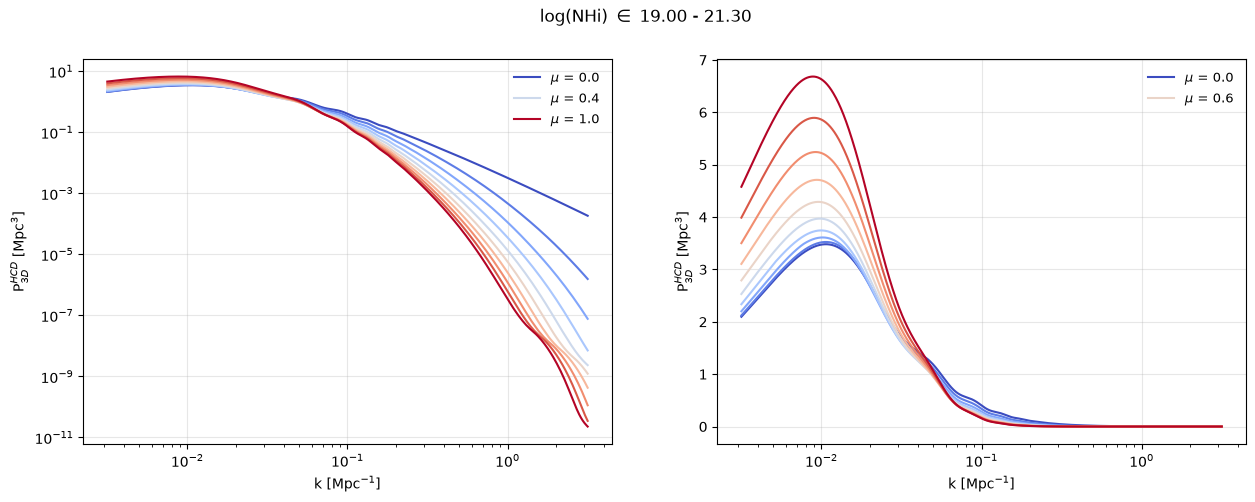

In [5]:
plt.figure(figsize=(15, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()));

plt.subplot(1, 2, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 4, 9]:
        plt.plot(k, p3d_hcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_hcd[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{HCD}$ [Mpc$^{3}$]');

plt.subplot(1, 2, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_hcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_hcd[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{HCD}$ [Mpc$^{3}$]');

<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_375/1419229140.py:10: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(k, p3d_lya[i, :], label = '$\mu$ = %.1f' %mu[i])
/tmp/ipykernel_375/1419229140.py:26: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(k, p3d_lya[i, :], label = '$\mu$ = %.1f' %mu[i])


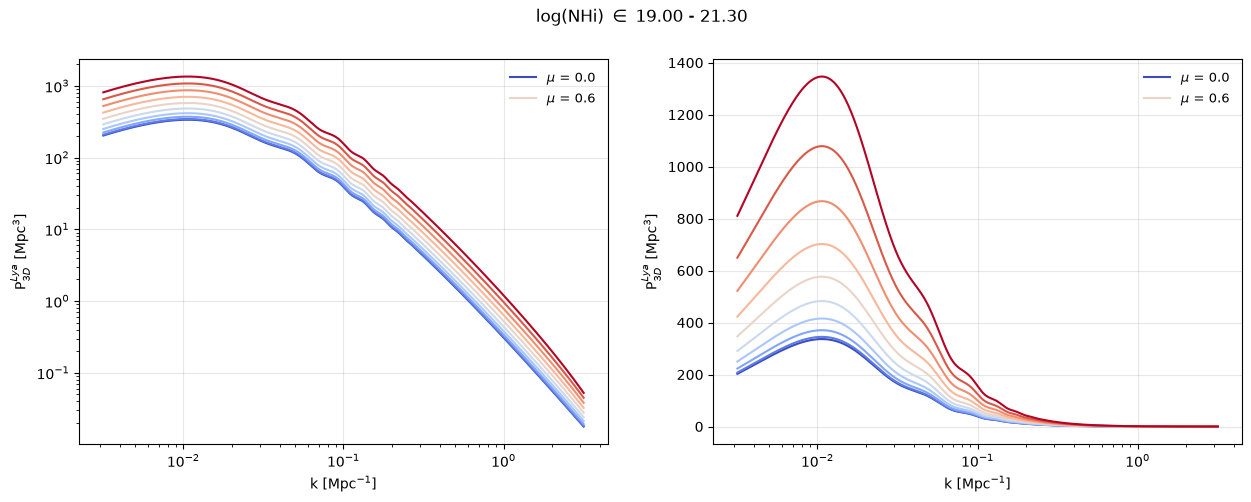

In [7]:
plt.figure(figsize=(15, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()));

plt.subplot(1, 2, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lya[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lya[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$ [Mpc$^{3}$]');

plt.subplot(1, 2, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lya[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lya[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$ [Mpc$^{3}$]');

<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_375/3450551791.py:10: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(k, p3d_lyahcd[i, :], label = '$\mu$ = %.1f' %mu[i])
/tmp/ipykernel_375/3450551791.py:26: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(k, p3d_lyahcd[i, :], label = '$\mu$ = %.1f' %mu[i])


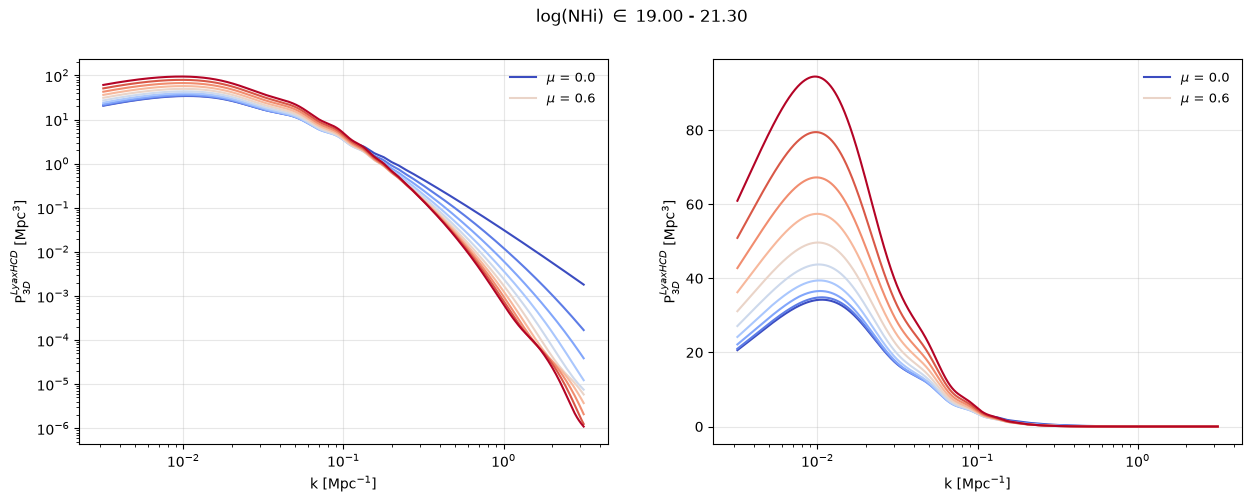

In [8]:
plt.figure(figsize=(15, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()));

plt.subplot(1, 2, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lyahcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lyahcd[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{LyaxHCD}$ [Mpc$^{3}$]');

plt.subplot(1, 2, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lyahcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lyahcd[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{LyaxHCD}$ [Mpc$^{3}$]');

<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_375/1889977345.py:10: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(k, p3d_tot[i, :], label = '$\mu$ = %.1f' %mu[i])
/tmp/ipykernel_375/1889977345.py:26: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(k, p3d_tot[i, :], label = '$\mu$ = %.1f' %mu[i])


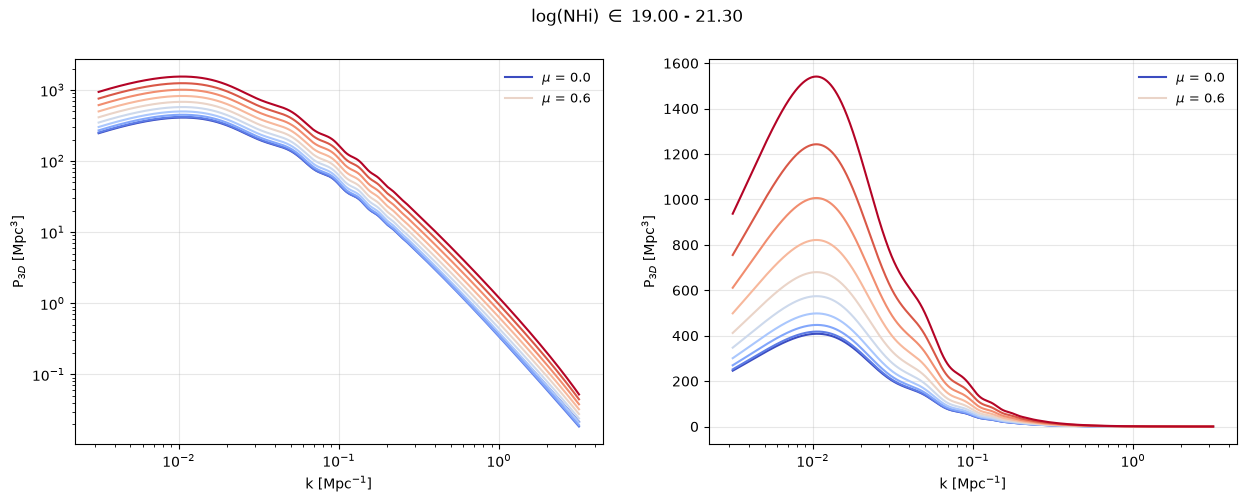

In [9]:
plt.figure(figsize=(15, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()));

plt.subplot(1, 2, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_tot[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_tot[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^{3}$]');

plt.subplot(1, 2, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_tot[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_tot[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^{3}$]');

## P1D

In [10]:
results_1d = p1d_model(bias_hcd, bias_lya, z, cosmo, NHirange, fNHiX)
w1 = _p3d_internal(bias_hcd, bias_lya, z, cosmo, NHirange, fNHiX)['w1']
k_los = results_1d['k_los']
p1d_tot = results_1d['p1d_tot']
p1d_lya = results_1d['p1d_lya']
p1d_hcd = results_1d['p1d_hcd']
p1d_lyahcd = results_1d['p1d_lyahcd']

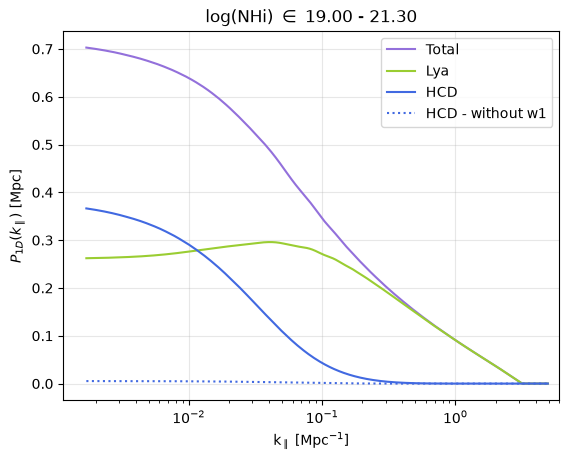

In [10]:
plt.plot(k_los, p1d_tot, color='mediumpurple', label='Total')
plt.plot(k_los, p1d_lya, color='yellowgreen', label='Lya')
plt.plot(k_los, p1d_hcd, color='royalblue', label='HCD')
plt.plot(k_los, p1d_hcd-w1, color='royalblue', linestyle=':', label='HCD - without w1')
plt.xscale('log')
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(right=6)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'$P_{1D}(k_\parallel)$ [Mpc]')
plt.title(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()));

## Px

In [13]:
r_bins = [0.6, 1.09, 1.97, 3.58, 6.5, 11.8]  # Mpc 
results_px = px_model(bias_hcd, bias_lya, z, cosmo, NHirange, fNHiX, r_bins)
k_los = results_px['k_los']
px_tot = results_px['px_tot']
px_lya = results_px['px_lya']
px_hcd = results_px['px_hcd']
px_lyahcd = results_px['px_lyahcd']

HCD contribution computed
Lya contribution computed
LyaxHCD contribution computed


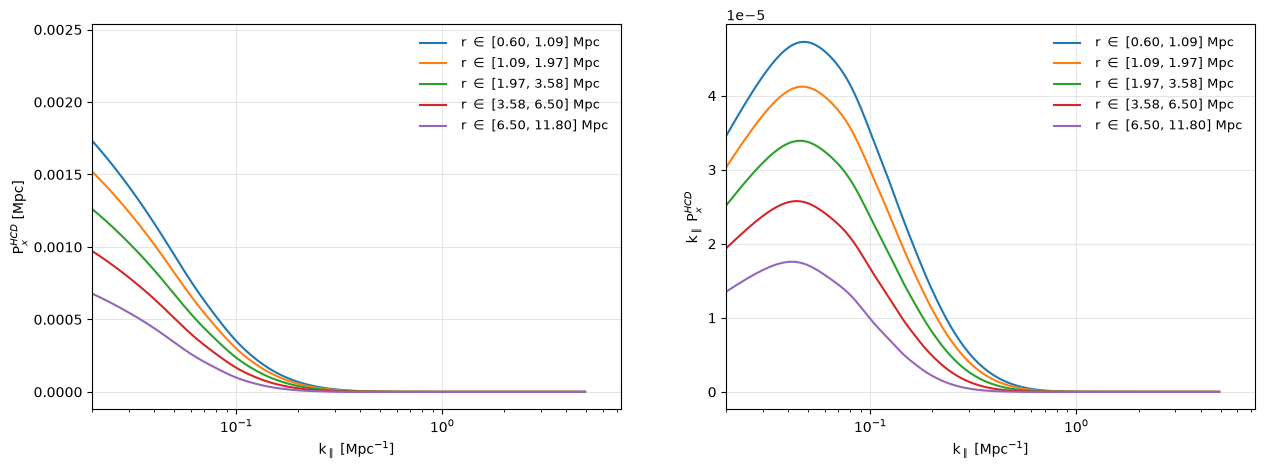

In [14]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
for i in np.arange(len(r_bins)-1):
    plt.plot(k_los, px_hcd[i, 0, :], label=f' r $\\in$ [%.2f, %.2f] Mpc' %(r_bins[i], r_bins[i+1]))
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlim(left=0.02)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'P$_{x}^{HCD}$ [Mpc]');

plt.subplot(1, 2, 2)
for i in np.arange(len(r_bins)-1):
    plt.plot(k_los, k_los*px_hcd[i, 0, :], label=f' r $\\in$ [%.2f, %.2f] Mpc' %(r_bins[i], r_bins[i+1]))
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlim(left=0.02)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'k$_\parallel$ P$_{x}^{HCD}$');

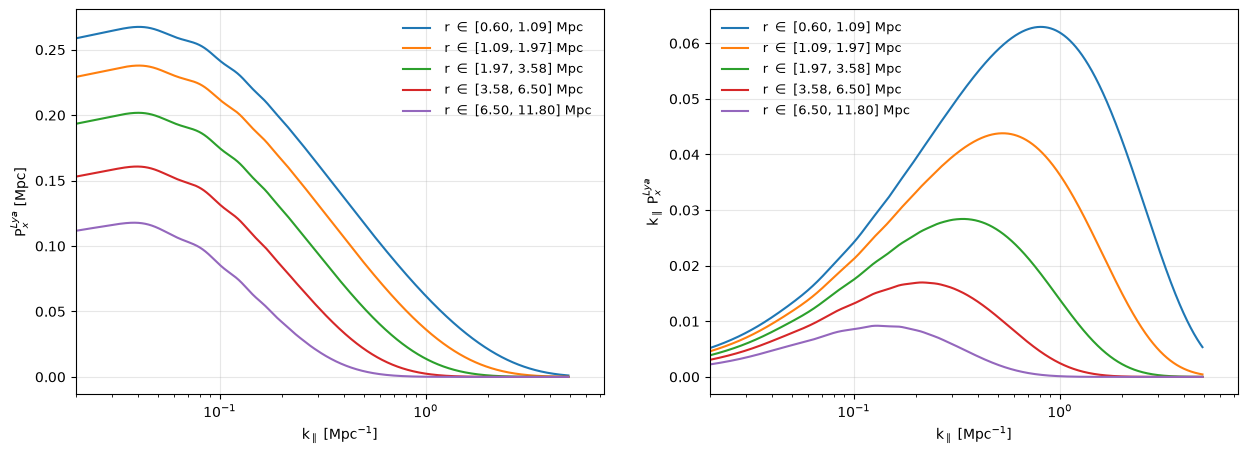

In [15]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
for i in np.arange(len(r_bins)-1):
    plt.plot(k_los, px_lya[i, 0, :], label=f' r $\\in$ [%.2f, %.2f] Mpc' %(r_bins[i], r_bins[i+1]))
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlim(left=0.02)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'P$_{x}^{Lya}$ [Mpc]');

plt.subplot(1, 2, 2)
for i in np.arange(len(r_bins)-1):
    plt.plot(k_los, k_los*px_lya[i, 0, :], label=f' r $\\in$ [%.2f, %.2f] Mpc' %(r_bins[i], r_bins[i+1]))
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlim(left=0.02)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'k$_\parallel$ P$_{x}^{Lya}$');

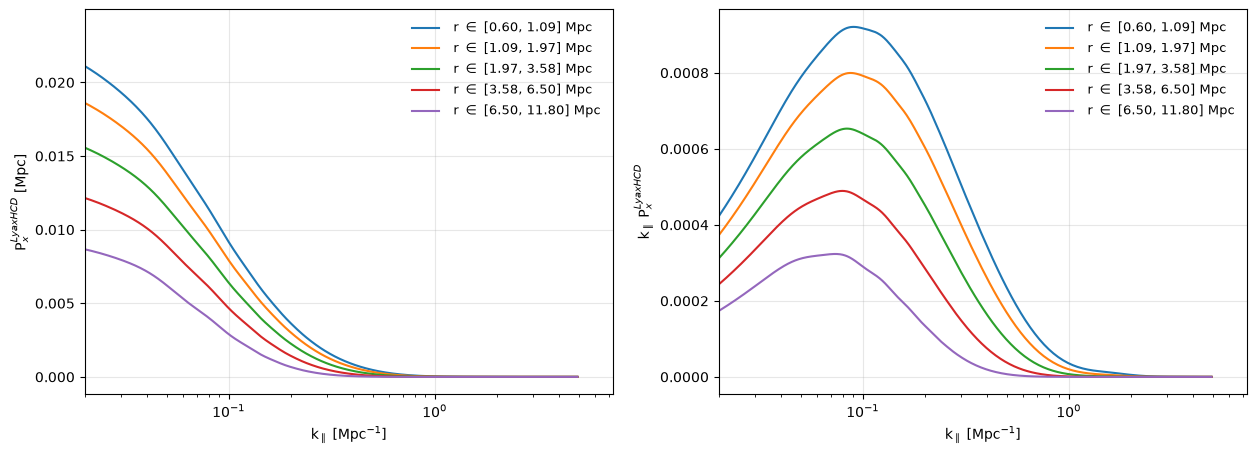

In [16]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
for i in np.arange(len(r_bins)-1):
    plt.plot(k_los, px_lyahcd[i, 0, :], label=f' r $\\in$ [%.2f, %.2f] Mpc' %(r_bins[i], r_bins[i+1]))
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlim(left=0.02)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'P$_{x}^{LyaxHCD}$ [Mpc]');

plt.subplot(1, 2, 2)
for i in np.arange(len(r_bins)-1):
    plt.plot(k_los, k_los*px_lyahcd[i, 0, :], label=f' r $\\in$ [%.2f, %.2f] Mpc' %(r_bins[i], r_bins[i+1]))
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlim(left=0.02)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'k$_\parallel$ P$_{x}^{LyaxHCD}$');

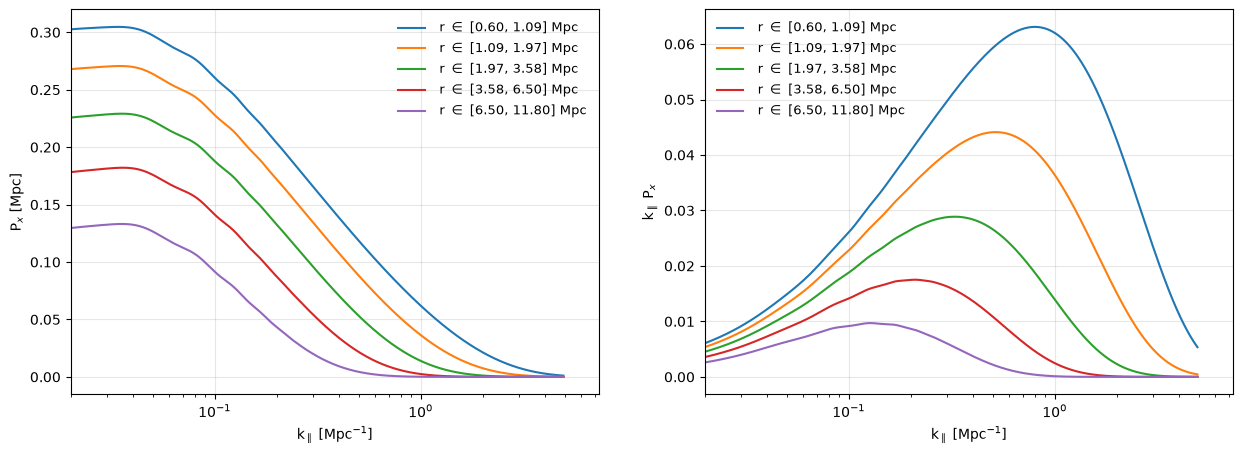

In [17]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
for i in np.arange(len(r_bins)-1):
    plt.plot(k_los, px_tot[i, 0, :], label=f' r $\\in$ [%.2f, %.2f] Mpc' %(r_bins[i], r_bins[i+1]))
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlim(left=0.02)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'P$_{x}$ [Mpc]');

plt.subplot(1, 2, 2)
for i in np.arange(len(r_bins)-1):
    plt.plot(k_los, k_los*px_tot[i, 0, :], label=f' r $\\in$ [%.2f, %.2f] Mpc' %(r_bins[i], r_bins[i+1]))
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlim(left=0.02)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'k$_\parallel$ P$_{x}$');

## Comparison with MW11 figures

/tmp/ipykernel_375/2247148651.py:35: RuntimeWarning: invalid value encountered in divide
  plt.plot(np.log10(k_los), (p1d_hcd-w1)/p1d_lya, color='red')
/tmp/ipykernel_375/2247148651.py:36: RuntimeWarning: divide by zero encountered in divide
  plt.plot(np.log10(k_los), w1/p1d_lya, color='blue')
/tmp/ipykernel_375/2247148651.py:36: RuntimeWarning: invalid value encountered in divide
  plt.plot(np.log10(k_los), w1/p1d_lya, color='blue')
/tmp/ipykernel_375/2247148651.py:39: RuntimeWarning: invalid value encountered in divide
  plt.plot(np.log10(k_los), p1d_lyahcd/p1d_lya, color='k')


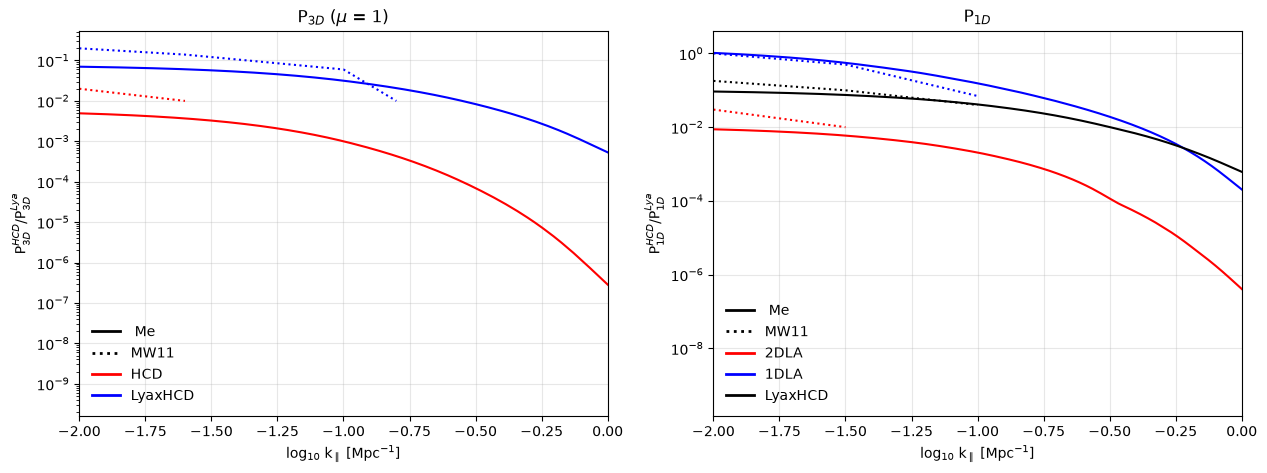

In [19]:
from matplotlib.lines import Line2D

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
k_mw11 = [-2, -1.6, -1, -0.8]
ratio_hcd_mw11 = [0.02, 0.01, np.nan, np.nan]
ratio_lyahcd_mw11 = [0.2, 0.14, 0.06, 0.01]

i = -1  # So that k = k_los
plt.plot(np.log10(k), p3d_hcd[i]/p3d_lya[i], color='red')
plt.plot(k_mw11, ratio_hcd_mw11, color='red', linestyle=':')
plt.plot(np.log10(k), p3d_lyahcd[i]/p3d_lya[i], color='blue')
plt.plot(k_mw11, ratio_lyahcd_mw11, color='blue', linestyle=':')

plt.yscale('log')
plt.grid(alpha=0.3)
handles = [Line2D([0], [0], color='black', lw=2, linestyle='-', label=' Me'),
    Line2D([0], [0], color='black', lw=2, linestyle=':', label='MW11'),
    Line2D([0], [0], color='red', lw=2, label='HCD'),
    Line2D([0], [0], color='blue', lw=2, label=r'LyaxHCD')]
plt.legend(handles=handles, frameon=False)
plt.xlabel(r'log$_{10}$ k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{HCD}$/P$_{3D}^{Lya}$')
plt.xlim(-2, 0)
plt.title(r'P$_{3D}$ ($\mu$ = 1)')


plt.subplot(1, 2, 2)
k_mw11 = [-2, -1.5, -1]
ratio_2dla_mw11 = [0.03, 0.01, np.nan]
ratio_lyahcd_mw11 = [0.18, 0.1, 0.04]
ratio_1dla_mw11 = [1, 0.5, 0.07]

plt.plot(np.log10(k_los), (p1d_hcd-w1)/p1d_lya, color='red')
plt.plot(np.log10(k_los), w1/p1d_lya, color='blue')
plt.plot(k_mw11, ratio_2dla_mw11, color='red', linestyle=':')
plt.plot(k_mw11, ratio_1dla_mw11, color='blue', linestyle=':')
plt.plot(np.log10(k_los), p1d_lyahcd/p1d_lya, color='k')
plt.plot(k_mw11, ratio_lyahcd_mw11, color='k', linestyle=':')

plt.yscale('log')
plt.xlim(-2, 0)
plt.grid(alpha=0.3)
handles = [Line2D([0], [0], color='black', lw=2, linestyle='-', label=' Me'),
    Line2D([0], [0], color='black', lw=2, linestyle=':', label='MW11'),
    Line2D([0], [0], color='red', lw=2, label='2DLA'),
    Line2D([0], [0], color='blue', lw=2, label=r'1DLA'),
    Line2D([0], [0], color='k', lw=2, label=r'LyaxHCD')]
plt.legend(handles=handles, frameon=False)
plt.xlabel(r'log$_{10}$ k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'P$_{1D}^{HCD}$/P$_{1D}^{Lya}$')
plt.title(r'P$_{1D}$');